# 03 - Extração de características radiómicas dos contornos

Este notebook extrai características radiómicas dos recortes CT e das máscaras da união dos médicos preparados no Notebook 02, para os conjuntos de treino LIDC e LNDb. Os candidatos de teste do LNDb não têm contornos disponíveis pelo que não se incluem neste notebook, mais informação ver **notebook5**.

Executar as células pela ordem apresentada: 

 1. Configurar a extração (*radiomics.yaml*)
 2. Calcular as tabelas de características 
 3. Rever a qualidade/informação extraída.
 
A modelação e a seleção de características são feitas no Notebook 04.


## 1. Configuração da extração e da região de interesse

Executar primeiro o Notebook 02. A célula seguinte carrega as configurações partilhadas e define o âmbito do processamento:

- `config/radiomics.yaml` define os parâmetros radiómicos, os filtros de imagem e as famílias de características.
- `config/scan_processing.json` define as regras dos recortes esperadas. Alterar este ficheiro não recria os recortes; se mudar a sua geometria, volte primeiro a executar o Notebook 02.
- `FIRST_SCAN_ONLY=False` processa as tabelas preparadas completas e reutiliza resultados compatíveis que já existam. Com `True`, a extração limita-se ao primeiro exame de cada conjunto e os resultados ficam apenas em memória: não são guardados como exportações completas nem são registadas novas configurações radiómicas.
- `SETTINGS_TAG=None`, forma de identificar e distinguir diferentes versões de extração, apoio a experiências realizadas.

A região de interesse (ROI) é definida pela união dos contornos dos médicos. Cada recorte CT e a respetiva máscara binária têm a mesma caixa delimitadora variável e o espaçamento configurado, atualmente **0,4 mm**. O recorte inclui ainda **6 mm de contexto CT por face**, conforme definido no Notebook 02. Os filtros podem usar esse contexto, mas as características são calculadas apenas nos voxels da máscara. O fundo da caixa e o preenchimento fora dos limites do exame não pertencem à ROI; não se aplica fecho convexo nem expansão da máscara. As matrizes são guardadas na ordem Z, Y, X. A interpolação permite uniformizar o espaçamento, mas não acrescenta detalhe anatómico à aquisição.

Se a máscara ocupar todo o recorte, acrescenta-se temporariamente uma orla de fundo para validação pelo PyRadiomics, sem aumentar a ROI. 


In [4]:
from pathlib import Path
import sys

PROJECT_ROOT = next(
    (
        p
        for p in (Path.cwd(), *Path.cwd().parents)
        if (p / "pyproject.toml").is_file() and (p / "src/lung_project").is_dir()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError("Start Jupyter from project/ or project/notebooks/")
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import logging
import numpy as np
import pandas as pd
from IPython.display import display
from lung_project.ct import CropRules
from lung_project.features import prepare_contour_features
from lung_project.prepared import list_contour_settings, radiomics_columns
from lung_project.progress import notebook_progress

FIRST_SCAN_ONLY = False
SETTINGS_TAG = None
radiomics_path = PROJECT_ROOT / "config/radiomics.yaml"
crop_rules = CropRules.from_json(PROJECT_ROOT / "config/scan_processing.json")
logging.getLogger("radiomics.glcm").setLevel(logging.ERROR)


## 2. Reutilização ou extração das características dos contornos

A célula seguinte executa `prepare_contour_features()`, que carrega e valida as tabelas de recortes, aplica o âmbito escolhido, configura o extrator e reutiliza ou calcula as tabelas de características. As regras dos recortes são verificadas automaticamente. 

Aqui, a seleção refere-se apenas aos conjuntos e exames a processar; não seleciona preditores nem aplica um novo filtro de malignidade de 1 a 5. A extração é tentada para os candidatos com recortes de contorno guardados. Os restantes mantêm-se nas tabelas com o respetivo estado, para auditoria. A seleção dos médicos e a união dos seus contornos já foram feitas nos passos anteriores.

Numa execução completa, cada conjunto pode reutilizar uma tabela em cache apenas quando coincidem a configuração efetiva, o ambiente e o código, a tabela de origem e os ficheiros CT e de máscara. Caso contrário, as características são calculadas e guardadas em `outputs/prepared/`, com os respetivos registos de proveniência. O modo de ensaio, limitado ao primeiro exame, devolve as tabelas em memória e não substitui as exportações completas.


In [5]:
feature_tables = prepare_contour_features(
    PROJECT_ROOT,
    radiomics_path,
    crop_rules,
    first_scan_only=FIRST_SCAN_ONLY,
    settings_tag=SETTINGS_TAG,
    progress=notebook_progress(),
)
display(list_contour_settings())


2690/2690 candidates

/home/pera/aulas/31c/labiacd/lung/project/src/lung_project/prepared.py:790: DtypeWarning: Columns (127: source_dicom_read_options) have mixed types. Specify dtype option on import or set low_memory=False.
  frame = pd.read_csv(
/home/pera/aulas/31c/labiacd/lung/project/src/lung_project/prepared.py:790: DtypeWarning: Columns (58: rating_review_action) have mixed types. Specify dtype option on import or set low_memory=False.
  frame = pd.read_csv(


lndb_train: reused verified contour features

,settings_id,tags,binWidth,normalize,image_types,lidc_exports,lidc_available_exports,lidc_missing_exports,lidc_current_inputs,lndb_train_exports,lndb_train_available_exports,lndb_train_missing_exports,lndb_train_current_inputs
0,837f2f660c2462d572cce8d77fa5f4f77ec1afe6c56351...,,25.00,False,Original,0,0,0,False,0,0,0,False
1,691c7ce35df858c622b9cf16df79ceeb1487c38506a193...,,25.00,False,Exponential;Gradient;LBP2D;LoG;Logarithm;Origi...,0,0,0,False,0,0,0,False
2,7ee917b39c8b8fe8e3b0ec9d9349003d4a934494ef1f20...,,10.00,True,LoG;Original;Wavelet,0,0,0,False,0,0,0,False
3,07a57fe8f02c18d069cff18d49aa733da64055c12df8b8...,,0.40,True,LoG;Original;Wavelet,0,0,0,False,0,0,0,False
4,1e6b2016629626854ad849c8635cf206b80306202d0636...,,0.04,True,LoG;Original;Wavelet,0,0,0,False,0,0,0,False
5,cdebd04e2041214493ef6a5b985fdb12badbde9b2e191c...,,10.00,False,Exponential;Gradient;LBP2D;LoG;Logarithm;Origi...,3,2,1,False,4,3,1,False
6,f667200f36ddb9cdbfd960b5dc22f3bb01689375eae8d7...,,25.00,False,Exponential;Gradient;LBP3D;LoG;Logarithm;Origi...,0,0,0,False,0,0,0,False
7,152f8584d3397e137f06bf6c776b0114aee20062eda9b4...,,10.00,False,Exponential;Gradient;LoG;Logarithm;Original;Sq...,3,3,0,True,2,2,0,True


### Tabelas devolvidas e configurações registadas

`feature_tables` contém as tabelas `lidc` e `lndb_train`, mantendo a ordem dos candidatos. As linhas conservam os rótulos e os metadados dos recortes, bem como a definição da ROI, os identificadores das configurações, o estado da extração e eventuais erros. Os candidatos LNDb anotados apenas por um ponto centroidal ficam com o estado `skipped_centroid_only` e sem características de contorno. No Notebook 04, só entram na modelação os candidatos com extração bem-sucedida e alvo de malignidade elegível, entre 1 e 5.

A tabela de `list_contour_settings()` apresenta os identificadores das configurações registadas, as etiquetas opcionais e a disponibilidade das exportações em cache. No modo de ensaio, mostra apenas o registo existente, não os resultados temporários. Comentários e formatação do YAML não alteram o identificador dos parâmetros efetivos; o checksum do ficheiro é guardado separadamente como proveniência.

As exportações completas são verificadas através dos hashes da própria tabela e dos dados de origem. Se os dados mudarem, a exportação ativa pode deixar de ser válida, mas os ficheiros históricos são preservados. Uma divergência entre o hash registado e o conteúdo do CSV gera um erro. Os detalhes da cache e da recuperação a partir de registos de experiências estão descritos na [metodologia](../docs/methodology.md).


## 3. Avaliação da qualidade da extração

A avaliação combina quatro perspetivas complementares:

- o resumo global apresenta candidatos, tentativas, extrações bem-sucedidas e cobertura de sucesso;
- a distribuição dos estados distingue resultados `ok`, erros e candidatos ignorados, incluindo a respetiva percentagem por conjunto;
- a cobertura de valores finitos é calculada apenas nas extrações `ok`, por família radiómica e por grupo: forma (`shape`), intensidade (`firstorder`) e textura (`glcm`, `glrlm`, `glszm`, `gldm`, `ngtdm`);
- a tabela de valores omissos por característica mantém também a contagem sobre todos os candidatos, para evidenciar a diferença entre omissões causadas por linhas ignoradas/erro e valores em falta numa extração bem-sucedida.

Os gráficos mostram a composição dos estados de extração e a percentagem de candidatos com todas as características finitas em cada família. Valores não finitos são tratados como omissos apenas numa cópia local; as exportações não são alteradas. Estes indicadores verificam a completude numérica, não a validade clínica nem a estabilidade entre aquisições. Este notebook não ajusta qualquer pré-processamento aos dados. A filtragem, a imputação e as restantes etapas aprendidas são ajustadas no Notebook 04, apenas com os pacientes da partição de ajuste.


,subset,roi,candidates,attempted,extracted,errors,success_pct_candidates,success_pct_attempted,predictors,features_with_missing_values_all_rows,features_with_missing_values_successful
0,lidc,contours,2690,2560,2560,0,95.17,100.0,758,758,0
1,lndb_train,contours,1219,712,712,0,58.41,100.0,758,758,0


,subset,status,candidates,percentage
0,lidc,ok,2560,95.17
1,lidc,skipped_excluded_by_review,125,4.65
2,lidc,skipped_excluded_source_geometry,5,0.19
3,lndb_train,ok,712,58.41
4,lndb_train,skipped_excluded_non_nodule,451,37.00
5,lndb_train,skipped_centroid_only,46,3.77
6,lndb_train,skipped_excluded_by_review,7,0.57
7,lndb_train,skipped_excluded_unknown_or_invalid_rating,3,0.25


,subset,group,families,features,successful_candidates,finite_values_pct,complete_candidates_pct,features_with_missing_values
0,lidc,Shape,shape,14,2560,100.0,100.0,0
1,lidc,First-order intensity,firstorder,144,2560,100.0,100.0,0
2,lidc,Texture,"glcm, glrlm, glszm, gldm, ngtdm",600,2560,100.0,100.0,0
3,lndb_train,Shape,shape,14,712,100.0,100.0,0
4,lndb_train,First-order intensity,firstorder,144,712,100.0,100.0,0
5,lndb_train,Texture,"glcm, glrlm, glszm, gldm, ngtdm",600,712,100.0,100.0,0


,subset,group,family,features,successful_candidates,finite_values_pct,complete_candidates_pct,features_with_missing_values
0,lidc,Shape,shape,14,2560,100.0,100.0,0
1,lidc,First-order intensity,firstorder,144,2560,100.0,100.0,0
2,lidc,Texture,glcm,192,2560,100.0,100.0,0
3,lidc,Texture,glrlm,128,2560,100.0,100.0,0
4,lidc,Texture,glszm,128,2560,100.0,100.0,0
5,lidc,Texture,gldm,112,2560,100.0,100.0,0
6,lidc,Texture,ngtdm,40,2560,100.0,100.0,0
7,lndb_train,Shape,shape,14,712,100.0,100.0,0
8,lndb_train,First-order intensity,firstorder,144,712,100.0,100.0,0
9,lndb_train,Texture,glcm,192,712,100.0,100.0,0


,subset,roi,group,family,features
0,lidc,contours,Shape,shape,14
1,lidc,contours,First-order intensity,firstorder,144
2,lidc,contours,Texture,glcm,192
3,lidc,contours,Texture,glrlm,128
4,lidc,contours,Texture,glszm,128
5,lidc,contours,Texture,gldm,112
6,lidc,contours,Texture,ngtdm,40
7,lndb_train,contours,Shape,shape,14
8,lndb_train,contours,First-order intensity,firstorder,144
9,lndb_train,contours,Texture,glcm,192


,subset,roi,feature,null_count,null_percentage,successful_null_count,successful_null_percentage
758,lndb_train,contours,original_shape_Elongation,507,41.59,0,0.0
759,lndb_train,contours,original_shape_Flatness,507,41.59,0,0.0
760,lndb_train,contours,original_shape_LeastAxisLength,507,41.59,0,0.0
761,lndb_train,contours,original_shape_MajorAxisLength,507,41.59,0,0.0
762,lndb_train,contours,original_shape_Maximum2DDiameterColumn,507,41.59,0,0.0
763,lndb_train,contours,original_shape_Maximum2DDiameterRow,507,41.59,0,0.0
764,lndb_train,contours,original_shape_Maximum2DDiameterSlice,507,41.59,0,0.0
765,lndb_train,contours,original_shape_Maximum3DDiameter,507,41.59,0,0.0
766,lndb_train,contours,original_shape_MeshVolume,507,41.59,0,0.0
767,lndb_train,contours,original_shape_MinorAxisLength,507,41.59,0,0.0


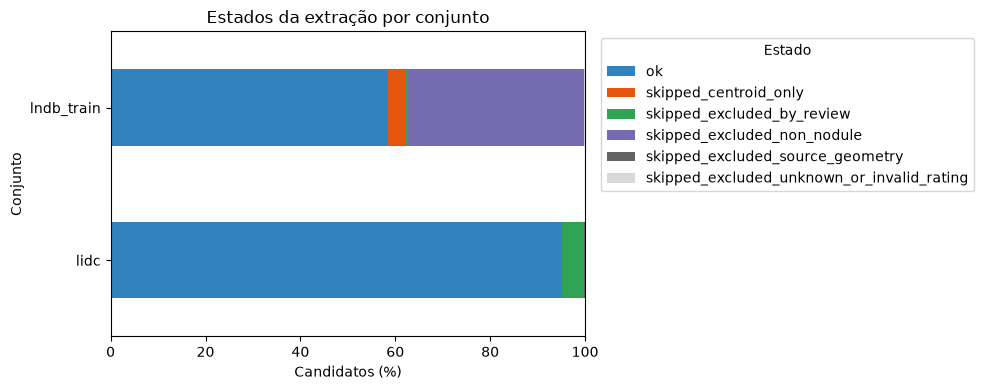

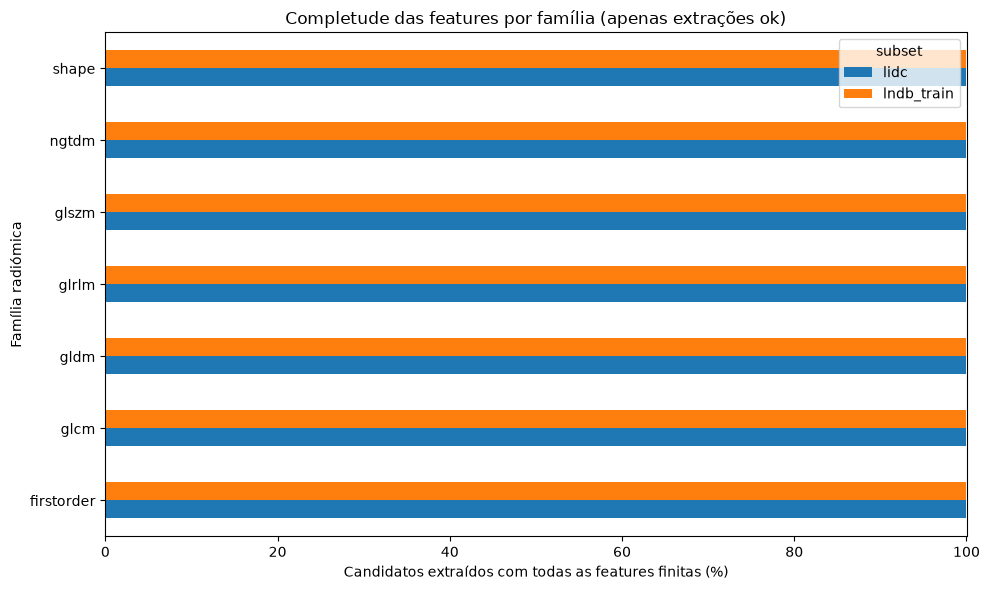

In [6]:
import matplotlib.pyplot as plt

feature_quality_rows = []
status_rows = []
family_rows = []
family_quality_rows = []
group_quality_rows = []
feature_nulls_rows = []
feature_group_by_family = {
    "shape": "Shape",
    "shape2D": "Shape",
    "firstorder": "First-order intensity",
    "glcm": "Texture",
    "glrlm": "Texture",
    "glszm": "Texture",
    "gldm": "Texture",
    "ngtdm": "Texture",
}

for subset, table in feature_tables.items():
    roi_variant = "contours"
    columns = radiomics_columns(table)
    numeric = table[columns].apply(pd.to_numeric, errors="raise").replace([np.inf, -np.inf], np.nan)
    status = table["extraction_status"].fillna("unknown").astype("string")
    successful = status.eq("ok")
    attempted = ~status.str.startswith("skipped_", na=False)
    numeric_successful = numeric.loc[successful]

    feature_quality_rows.append(
        {
            "subset": subset,
            "roi": roi_variant,
            "candidates": len(table),
            "attempted": int(attempted.sum()),
            "extracted": int(successful.sum()),
            "errors": int(status.str.startswith("error", na=False).sum()),
            "success_pct_candidates": round(successful.mean() * 100, 2),
            "success_pct_attempted": round(successful.sum() / attempted.sum() * 100, 2) if attempted.any() else np.nan,
            "predictors": len(columns),
            "features_with_missing_values_all_rows": int(numeric.isna().any().sum()),
            "features_with_missing_values_successful": int(numeric_successful.isna().any().sum()),
        }
    )

    for status_name, count in status.value_counts(dropna=False).items():
        status_rows.append(
            {
                "subset": subset,
                "status": str(status_name),
                "candidates": int(count),
                "percentage": round(count / len(table) * 100, 2) if len(table) else np.nan,
            }
        )

    columns_by_family = {}
    for column in columns:
        family = column.split("_", 2)[1]
        columns_by_family.setdefault(family, []).append(column)

    for family, family_columns in columns_by_family.items():
        group = feature_group_by_family.get(family, "Other")
        family_rows.append(
            {"subset": subset, "roi": roi_variant, "group": group, "family": family, "features": len(family_columns)}
        )
        values = numeric_successful[family_columns]
        family_quality_rows.append(
            {
                "subset": subset,
                "group": group,
                "family": family,
                "features": len(family_columns),
                "successful_candidates": len(values),
                "finite_values_pct": round(values.notna().to_numpy().mean() * 100, 2) if values.size else np.nan,
                "complete_candidates_pct": round(values.notna().all(axis=1).mean() * 100, 2) if len(values) else np.nan,
                "features_with_missing_values": int(values.isna().any().sum()),
            }
        )

    for group in ("Shape", "First-order intensity", "Texture", "Other"):
        group_families = [
            family for family in columns_by_family
            if feature_group_by_family.get(family, "Other") == group
        ]
        group_columns = [column for family in group_families for column in columns_by_family[family]]
        if not group_columns:
            continue
        values = numeric_successful[group_columns]
        group_quality_rows.append(
            {
                "subset": subset,
                "group": group,
                "families": ", ".join(group_families),
                "features": len(group_columns),
                "successful_candidates": len(values),
                "finite_values_pct": round(values.notna().to_numpy().mean() * 100, 2) if values.size else np.nan,
                "complete_candidates_pct": round(values.notna().all(axis=1).mean() * 100, 2) if len(values) else np.nan,
                "features_with_missing_values": int(values.isna().any().sum()),
            }
        )

    null_counts = numeric.isna().sum()
    null_pcts = numeric.isna().mean() * 100
    successful_null_counts = numeric_successful.isna().sum()
    successful_null_pcts = numeric_successful.isna().mean() * 100 if len(numeric_successful) else pd.Series(0.0, index=columns)
    for column in columns:
        feature_nulls_rows.append(
            {
                "subset": subset,
                "roi": roi_variant,
                "feature": column,
                "null_count": int(null_counts[column]),
                "null_percentage": round(float(null_pcts[column]), 2),
                "successful_null_count": int(successful_null_counts[column]),
                "successful_null_percentage": round(float(successful_null_pcts[column]), 2),
            }
        )

df_feature_quality = pd.DataFrame(feature_quality_rows)
df_extraction_status = pd.DataFrame(status_rows)
df_family_counts = pd.DataFrame(family_rows)
df_family_quality = pd.DataFrame(family_quality_rows)
df_group_quality = pd.DataFrame(group_quality_rows)
df_feature_nulls = pd.DataFrame(feature_nulls_rows)

display(df_feature_quality)
display(df_extraction_status.sort_values(["subset", "percentage"], ascending=[True, False]))
display(df_group_quality)
display(df_family_quality)
display(df_family_counts)
display(
    df_feature_nulls.sort_values(
        ["successful_null_percentage", "null_percentage"], ascending=False
    ).groupby("subset", group_keys=False).head(20)
)

status_plot = df_extraction_status.pivot(
    index="subset", columns="status", values="percentage"
).fillna(0)
status_order = ["ok"] + sorted(column for column in status_plot.columns if column != "ok")
status_plot = status_plot.reindex(columns=status_order)
status_plot.plot(kind="barh", stacked=True, figsize=(10, 4), colormap="tab20c")
plt.xlabel("Candidatos (%)")
plt.ylabel("Conjunto")
plt.title("Estados da extração por conjunto")
plt.legend(title="Estado", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xlim(0, 100)
plt.tight_layout()
plt.show()

family_coverage_plot = df_family_quality.pivot(
    index="family", columns="subset", values="complete_candidates_pct"
)
family_coverage_plot.plot(kind="barh", figsize=(10, 6), xlim=(0, 100))
plt.xlabel("Candidatos extraídos com todas as features finitas (%)")
plt.ylabel("Família radiómica")
plt.title("Completude das features por família (apenas extrações ok)")
plt.tight_layout()
plt.show()


1. **LIDC:** dos 2 690 candidatos, 2 561 têm estado `ok` (95,20%), 125 foram ignorados por exclusão na revisão (`skipped_excluded_by_review`) e 4 têm `skipped_mask_error`. A cobertura elevada não elimina a necessidade de auditar os erros de máscara.

2. **LNDb de treino:** dos 1 219 candidatos, 719 têm estado `ok` (58,98%), 451 têm `skipped_excluded_non_nodule`, 46 têm `skipped_centroid_only` e 3 têm `skipped_excluded_unknown_or_invalid_rating`. As anotações apenas centroidais não fornecem uma segmentação volumétrica para esta extração; podem ser tratadas pelo fluxo esférico independente do Notebook 05.

Estas contagens descrevem as exportações atuais. A diferença de cobertura reflete as categorias de anotação e as regras de processamento; não demonstra, por si só, superioridade da qualidade de um conjunto de dados. O estado da extração também não substitui a verificação de elegibilidade do alvo no Notebook 04.


## 4. Experimentações com PyRadiomics

Esta secção distingue a configuração atual, verificável em `config/radiomics.yaml` e no extrator efetivo, das observações históricas registadas durante a exploração. As escolhas procuram equilibrar a informação extraída, a cobertura dos candidatos e o custo computacional. As comparações históricas abaixo não identificam todas as execuções e não demonstram isoladamente o efeito de cada alteração; os resultados atuais de modelação devem ser consultados no Notebook 04.


### 4.1. Configurações avaliadas e estado atual

As tabelas resumem os filtros e famílias considerados no projeto. O estado atual decorre do YAML e dos argumentos efetivos do extrator. As opções descritas como testadas pertencem ao histórico de exploração, não a novas experiências executadas neste notebook.

#### Tabela A: Filtros e transformações de imagem

| Filtro / Image Type | Transformação implementada | Exploração histórica | Estado atual |
| :--- | :--- | :--- | :--- |
| **Original** | Intensidades CT do recorte, já interpoladas e limitadas ao intervalo configurado, sem novo filtro. | Referência | **Ativo** |
| **Laplacian of Gaussian (LoG)** | Filtro 3D de Laplaciano de Gaussiana; sigma em mm controla a escala de suavização, não um raio rígido da ROI. | Escalas até 10 mm | **Ativo: sigma 1 e 2 mm** |
| **Wavelet** | Decomposição em bandas de frequências e direções; os eixos processados dependem da configuração, incluindo `force2D`. | `coif1`, `start_level=0`, `level=1`; exploração 3D com `force2D=False` | **Não configurado** |
| **Gradient** | Magnitude do gradiente espacial, considerando o espaçamento (`gradientUseSpacing=True`). | Utilizado | **Ativo** |
| **Square** | Quadrado das intensidades com reescala dependente da imagem; perde o sinal dos valores negativos. | Parâmetros predefinidos | **Ativo** |
| **Logarithm** | Logaritmo do valor absoluto mais um, com preservação do sinal e reescala dependente da imagem. | Parâmetros predefinidos | **Ativo** |
| **Square Root** | Raiz quadrada do valor absoluto, com preservação do sinal e reescala dependente da imagem. | Parâmetros predefinidos | **Ativo** |
| **Exponential** | Exponencial com fator de escala dependente da imagem. | Parâmetros predefinidos | **Ativo** |
| **Local Binary Pattern 3D (LBP3D)** | Descritores locais de textura volumétrica. | Considerado na exploração | **Não configurado** |



#### Tabela B: Características Radiómicas (PyRadiomics Feature Classes)

| Família / Class | Atributos Extraídos e Propriedades | N.º Features / Filtro | Estado no Projeto |
| :--- | :--- | :--- | :--- |
| **First Order Statistics** | Estatística descritiva de intensidade da ROI (Média, Mediana, Variância, Skewness, Kurtosis, Energy, Entropy, 90th Percentile). | 18 features | **Testado / Ativo** |
| **Shape 3D** | Atributos geométricos volumétricos da união dos contornos (Volume, Surface Area, Sphericity, Elongation, Flatness e comprimentos dos eixos). | 14 features (apenas Original) | **Ativo** |
| **Shape 2D** | Descritores geométricos 2D; a família `shape2D` é explicitamente removida pelo extrator de contornos. | 0 features extraídas | **Desativado** |
| **GLCM** *(Gray Level Co-occurrence Matrix)* | Textura de segunda ordem: frequência de co-ocorrência de pares de intensidades (Contraste, Homogeneidade, Correlação, Energy, Dissimilarity). | 24 features | **Testado / Ativo** |
| **GLRLM** *(Gray Level Run Length Matrix)* | Mede o comprimento de sequências contínuas de voxels com o mesmo nível de cinzento (Short/Long Run Emphasis, Run Percentage). | 16 features | **Testado / Ativo** |
| **GLSZM** *(Gray Level Size Zone Matrix)* | Avalia o tamanho de zonas ligadas de voxels que partilham a mesma intensidade (Small/Large Zone Emphasis, Zone Variance). | 16 features | **Testado / Ativo** |
| **NGTDM** *(Neighboring Gray Tone Difference Matrix)* | Mede a diferença entre a intensidade de um voxel e a média dos seus vizinhos próximos (Coarseness, Contrast, Busyness, Complexity, Strength). | 5 features | **Testado / Ativo** |
| **GLDM** *(Gray Level Dependence Matrix)* | Conta o número de voxels dependentes dentro de uma distância em relação ao voxel central (Dependence Non-Uniformity, Large Dependence Emphasis). | 14 features | **Testado / Ativo** |

#### Tabela C: Configurações globais e processamento anterior à extração

| Parâmetro / Setting | Função e valor efetivo atual | Origem / estado |
| :--- | :--- | :--- |
| **`binWidth`** | Largura fixa de discretização igual a `10`, nas unidades da imagem de cada filtro. Na imagem original corresponde a 10 HU; as imagens transformadas têm outra escala. | YAML |
| **`resampledPixelSpacing`** | `None`: o PyRadiomics não volta a reamostrar os recortes. A grelha isotrópica de **0,4 mm** já foi criada no Notebook 02. | Predefinição do extrator; grelha definida em `scan_processing.json` |
| **`interpolator`** | O extrator mantém `sitkBSpline`, mas a reamostragem de imagem está desativada por `resampledPixelSpacing=None`. No Notebook 02 usa-se interpolação **linear para CT** e **vizinho mais próximo para máscaras**. | Distinguir o valor do extrator da interpolação anterior |
| **`padDistance`** | Valor efetivo `5`, em **voxels**, para o contexto da reamostragem interna do PyRadiomics. Não define a margem CT deste projeto nem garante que esta seja criada. | Predefinição do extrator; não é a origem dos 6 mm |
| **`contour_margin_mm`** | **6 mm de contexto CT por face**, criados no Notebook 02; o fundo acrescentado à máscara mantém valor zero. | Configuração dos recortes, não argumento do PyRadiomics |
| **`voxelArrayShift`** | `0`: não se acrescenta um deslocamento nas características de energia que usam este parâmetro. Não é uma transformação global que torne toda a imagem positiva. | Predefinição; sem deslocamento adicional |
| **`label`** | **`1` (ativo)**: o PyRadiomics extrai características dos voxels com valor 1 na máscara binária; 0 é fundo. Este parâmetro seleciona a ROI e não representa a classificação de malignidade. | Predefinição ativa, mesmo sem entrada no YAML |
| **`correctMask`** | `True`: permite tentar corrigir diferenças de geometria da máscara por reamostragem, quando a ROI é válida na imagem. Não corrige a qualidade clínica da segmentação. | YAML |
| **`force2D` / `force2Ddimension`** | `True` / `0`: restringe as vizinhanças de textura ao plano Y,X, excluindo a direção Z das relações espaciais. Não executa uma análise totalmente 2D nem desativa todos os filtros em Z. | `force2D` no YAML; dimensão predefinida |
| **`minimumROISize`** | `5`: nesta versão, a verificação rejeita ROI com **5 voxels ou menos**. | YAML; condição implementada `roiSize <= minSize` |
| **`resegmentRange`** | Ausente: não há exclusão de voxels da ROI por este parâmetro. O CT já foi limitado a **[-1000, 400] HU** antes da extração, sem retirar voxels da máscara. | Distinguir resegmentação de limitação de intensidades |
| **`normalize` / `normalizeScale`** | `False` / `1`: não se aplica normalização Z-score à imagem nesta extração. A normalização de preditores durante a modelação é outra operação. | `normalize` no YAML; escala predefinida |

**Dimensionalidade.** Os dados continuam a ser volumes: as estatísticas de primeira ordem usam a ROI volumétrica, a forma é 3D e o LoG usa um filtro 3D. `force2D=True` limita as relações de vizinhança usadas nas texturas; não elimina a informação de todas as fatias nem implica extração independente seguida de uma média de resultados por fatia. As contagens de forma são calculadas na imagem Original, não repetidas para cada filtro.


### 4.2. Interpretação das escolhas e observações históricas

Os números históricos seguintes preservam os registos da exploração. Sem identificar as execuções, as coortes e as restantes configurações correspondentes, não se deve atribuir uma diferença de desempenho a uma única alteração nem apresentá-la como resultado atual.

1. **LoG.** Foram registados ensaios com sigma até 10 mm, incluindo falhas ou valores em falta em 2 180 candidatos LIDC para 10 mm e 1 049 candidatos LNDb para 5 mm. Estas contagens são históricas e não foram recalculadas nesta execução. Sigma controla a escala da Gaussiana; não é o raio do nódulo nem garante que o suporte do filtro caiba na lesão. O PyRadiomics pode omitir escalas incompatíveis com as dimensões da imagem. A configuração atual usa sigma de **1 e 2 mm**, sobre o volume com contexto CT de **6 mm por face**. Esse contexto é uma escolha prática, não uma garantia de ausência de efeitos de fronteira.

2. **Wavelet e vizinhanças de textura.** A exploração combinou Wavelet 3D com `force2D=False`, tendo sido registadas aproximadamente 1 800 características contra cerca de 800 e tempos de 3h30 contra 30 minutos. Foram ainda registadas QWK 0,687 versus 0,701, accuracy 56,2% versus 58,6%, aumento de F1 macro de cerca de 0,04, MAE 0,511 versus 0,469 e RMSE 0,822 versus 0,767. Como foram alterados filtros e dimensionalidade em conjunto, estas observações não isolam o efeito de `force2D`, não demonstram que o eixo Z seja ruído e não constituem um teste de significância. Atualmente, Wavelet está desativado, as vizinhanças de textura são em plano e mantêm-se o processamento volumétrico e as características de forma 3D. As exportações atuais contêm **758 preditores**: 14 de forma e 93 descritores para cada uma das oito imagens (Original, dois LoG e cinco outras transformações).

3. **Limitação de HU.** O Notebook 02 limita as intensidades CT a **[-1000, 400] HU** depois da interpolação, mantendo a máscara. Isso reduz a influência de valores extremos nas estatísticas e nos filtros, mas também satura diferenças entre estruturas acima de 400 HU. Um valor extremo não prova, por si só, erro de segmentação ou de aquisição. A melhoria histórica de erro de cerca de 0,600 para 0,500 foi registada durante a exploração; sem uma comparação identificada com as restantes condições fixas, não pode ser atribuída exclusivamente à limitação de HU. Esta operação não é `resegmentRange`: os voxels não são removidos da ROI.

4. **Interpolação.** A implementação atual usa interpolação **linear para CT** e **vizinho mais próximo para máscaras** no Notebook 02. Vizinho mais próximo preserva os valores discretos da máscara; não se trata de um classificador KNN. A exploração com `sitkBSpline` não registou diferenças assinaláveis, mas falta uma comparação identificada para quantificá-las. Interpolação linear ou cúbica e dimensionalidade das vizinhanças de textura são decisões distintas: uma análise com `force2D=True` não impede interpolação cúbica. O valor `sitkBSpline` do extrator não provoca nova reamostragem de imagem quando `resampledPixelSpacing=None`.

5. **Espaçamento.** Foram considerados o espaçamento nativo, 1 mm isotrópico e 0,4 mm isotrópico. Manter o espaçamento nativo evita essa interpolação, mas conserva diferenças de resolução entre exames; 1 mm pode reduzir a representação de nódulos pequenos. A grelha atual de **0,4 mm** é criada nos recortes do Notebook 02 e reutilizada aqui. Aumenta a densidade de amostragem, sem criar detalhe anatómico original nem garantir melhor desempenho. Definir `resampledPixelSpacing=None` neste extrator significa usar a grelha já guardada, não recuperar o espaçamento nativo. A [IBSI](https://ibsi.readthedocs.io/) é uma referência metodológica para padronização e sensibilidade das características; a implementação efetiva de discretização deve ser distinguida da convenção IBSI.

6. **Largura dos bins.** A exploração registou `binWidth` 10 e 25; a configuração atual é **10**. Bins mais estreitos podem aumentar a dimensão das matrizes. Bins mais largos reduzem os níveis distintos, podendo perder diferenças de intensidade. O valor 10 foi escolhido durante a exploração como compromisso prático. A afirmação de superioridade preditiva requer os resultados das execuções correspondentes; não existe aqui uma demonstração de que 10 seja universalmente melhor que 25. Na imagem Original, a largura é em HU; nas imagens transformadas aplica-se às intensidades produzidas por cada filtro, não a intervalos de HU originais.


## Continuação no Notebook 04

Antes de avançar, conclua uma execução completa com `FIRST_SCAN_ONLY=False`; o modo de ensaio não atualiza as exportações completas. O Notebook 04 verifica as características e a configuração guardadas e regista-as numa experiência com nome próprio.

Depois de alterar `radiomics.yaml`, volte a executar este notebook e, em seguida, o Notebook 04. Se alterar a geometria dos recortes, execute primeiro o Notebook 02. Após modificar funções Python do projeto, reinicie os kernels dos notebooks envolvidos para garantir que a execução usa o código atualizado.
